In [1]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/joyix/Documents/Jupyter/venv/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## instructions
Fishing bandit practice

You have 10 ponds and 1,000 fishing days. Each pond has an unknown probability of giving a fish. Your goal is to maximize the total number of fish caught.
1. Implement the four policy functions: random, e-greedy, softmax, and ucb. Each must return one pond index.
2. Use only estimated_means, counts, t, and rng to choose an action. Do not use the true probabilities inside your policy.
3. Run the comparison cell to evaluate each policy across 100 runs. Compare average total reward, variability, best pond selections, and the reward curves.
4. Experiment with epsilon, temperature (tau), and the ucb bonus. 
Baselines: Tte random policy’s expected total is 340 fish; always choosing the true best pond would yield 600 fish on average.

## starter code

In [2]:
probabilities = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.60
]

In [3]:
import numpy as np
import matplotlib.pyplot as plt


class FishingBandit:
    def __init__(self, probabilities, seed=42):
        """
        probabilities[i] is the true probability of catching
        a fish at pond i. The agent should not access these.
        """
        self._probabilities = np.asarray(probabilities)
        self.n_arms = len(probabilities)
        self.rng = np.random.default_rng(seed)

    def pull(self, action):
        """
        Choose a pond and receive:
            1 = caught a fish
            0 = caught no fish
        """
        probability = self._probabilities[action]
        return int(self.rng.random() < probability)

## baseline

In [4]:
def random_policy(estimated_means, counts, t, rng):
    return rng.integers(0, len(estimated_means))

## hedging policies
For each policy, return the pond’s index. When several actions tie for the highest score, choose randomly among the tied actions so the first index isn’t always favoured.

In [5]:
# give actions with higher estimated means a higher chance of being chosen
def softmax_policy(estimated_means, counts, t, rng, tau=0.1):
    # TODO:
    # 1. Convert estimated means into probabilities with softmax.
    # 2. Sample one pond using those probabilities.
    tot = 0
    softmax = []
    for mu in estimated_means:
        num = np.e**(mu/tau)
        tot += num
        softmax.append(num)

    softmax = [num / tot for num in softmax]
    return rng.choice(len(estimated_means), p=softmax)

In [6]:
# with probability epsilon, explore: choose a random pond
# otherwise, exploit: choose a pond with the highest estimated average
# start with e = 0.1
def epsilon_greedy(estimated_means, counts, t, rng, epsilon=0.1):
    # TODO:
    # With probability epsilon, select a random pond.
    # Otherwise, select a pond with the highest estimated mean.
    choice = rng.choice([0, 1], p=[epsilon, 1-epsilon])
    if choice == 0:
        return random_policy(estimated_means, counts, t, rng)
    else: 
        return rng.choice(np.flatnonzero(estimated_means == np.max(estimated_means)))

In [7]:
# exploration bonus added to each estimated mean. choose action with the highest UCB score
# start time at t = 1, and try every arm once before using the formula -- avoids taking ln(0) or div by zero
def ucb_policy(estimated_means, counts, t, rng):
    # TODO:
    # 1. If any pond has never been tried, choose one of them.
    # 2. Otherwise, compute each pond's UCB score.
    # 3. Choose a pond with the highest score.
    if 0 in counts: 
        unvisited = np.flatnonzero(counts == 0)
        return rng.choice(unvisited)

    ucb_list = []
    for i, mu in enumerate(estimated_means):
        ucb = mu + np.sqrt(np.log(t)/counts[i])
        ucb_list.append(ucb)

    ucb_list = np.array(ucb_list)
    best_indices = np.flatnonzero(ucb_list == np.max(ucb_list))

    return rng.choice(best_indices)

## simulation

In [8]:
def run_experiment(policy, probabilities, horizon, seed):
    env = FishingBandit(probabilities, seed=seed)

    # separate RNG for the policy's random decisions.
    policy_rng = np.random.default_rng(seed + 10_000)

    counts = np.zeros(env.n_arms, dtype=int)
    estimated_means = np.zeros(env.n_arms)
    rewards = []

    for t in range(1, horizon + 1):
        action = policy(estimated_means, counts, t, policy_rng)

        reward = env.pull(action)

        counts[action] += 1
        estimated_means[action] += (reward - estimated_means[action]) / counts[action]

        rewards.append(reward)

    return np.array(rewards), counts, estimated_means

## comparison

Random: avg reward = 329.3, std = 15.3, avg best-arm picks = 99.9
Epsilon-greedy: avg reward = 516.9, std = 52.8, avg best-arm picks = 540.2
Softmax: avg reward = 510.3, std = 44.0, avg best-arm picks = 498.6
UCB: avg reward = 494.4, std = 20.4, avg best-arm picks = 502.0


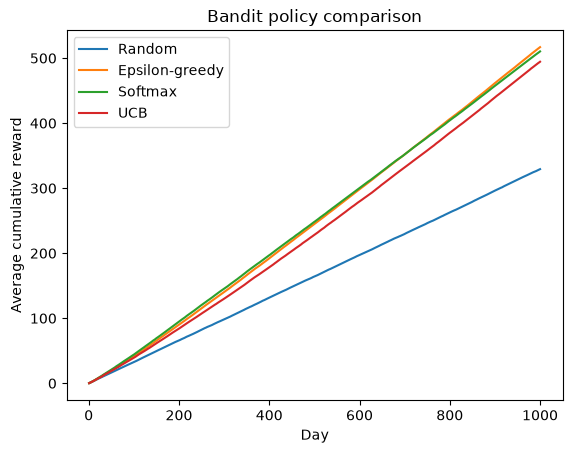

In [9]:
# run after implementing all four policy functions.
policies = {
    "Random": random_policy,
    "Epsilon-greedy": epsilon_greedy,
    "Softmax": softmax_policy,
    "UCB": ucb_policy,
}

HORIZON = 1_000
N_RUNS = 100
best_arm = np.argmax(probabilities)  # Used for evaluation only.

for name, policy in policies.items():
    all_curves = []
    total_rewards = []
    best_arm_counts = []

    for seed in range(N_RUNS):
        rewards, counts, _ = run_experiment(
            policy, probabilities, HORIZON, seed
        )

        all_curves.append(np.cumsum(rewards))
        total_rewards.append(rewards.sum())
        best_arm_counts.append(counts[best_arm])

    average_curve = np.mean(all_curves, axis=0)
    plt.plot(range(1, HORIZON + 1), average_curve, label=name)

    print(
        f"{name}: "
        f"avg reward = {np.mean(total_rewards):.1f}, "
        f"std = {np.std(total_rewards):.1f}, "
        f"avg best-arm picks = {np.mean(best_arm_counts):.1f}"
    )

plt.xlabel("Day")
plt.ylabel("Average cumulative reward")
plt.title("Bandit policy comparison")
plt.legend()
plt.show()